In [37]:
import numpy as np
import matplotlib.pyplot as plt
import os

In [38]:
def quant_ampl_dist(route, channels, addr_width, dac_width, save=True):
    """
    Generate a quantized amplitude distribution LUT from a text spectrum.

    Parameters
    ----------
    route : str
        Path to the input spectrum text file.
    channels : int
        Number of spectrum channels to process.
    addr_width : int
        LUT address width in bits. LUT length is 2**addr_width.
    dac_width : int
        DAC resolution in bits.
    save : bool
        If True, save the generated LUT as a binary file.

    Returns
    -------
    np.ndarray
        Quantized amplitude distribution LUT.
    """

    # Load input spectrum
    spec = np.loadtxt(route)
    spec = spec[:channels]

    # Generate output filename
    name = os.path.splitext(os.path.basename(route))[0]
    output_path = f"../specs/{name}.bin"

    # Define LUT and DAC limits
    target_length = 2**addr_width
    dac_max = 2**dac_width - 2

    # Normalize spectrum to obtain channel probabilities
    freqs = spec / np.sum(spec)

    # Quantize probabilities to integer frequencies
    freqs_int = np.round(freqs * target_length).astype(np.int64)

    # Correct rounding error to guarantee exact LUT size
    diff = target_length - np.sum(freqs_int)

    if diff != 0:
        idx = np.argmax(freqs_int)
        freqs_int[idx] += diff

    # Generate frequency-expanded channel lookup table
    ch_freqs = np.repeat(np.arange(len(spec)), freqs_int)

    counts = np.bincount(ch_freqs, minlength=channels)
    
    # Scale channel indices to DAC resolution
    ch_freqs = (
        ch_freqs * dac_max / ch_freqs.max()
    ).astype(np.uint32)

    # Verify generated LUT properties
    print("TARGET_LENGTH :", target_length)
    print("REAL_LENGTH   :", len(ch_freqs))
    print("POWER OF 2    :", (len(ch_freqs) & (len(ch_freqs) - 1)) == 0)
    print("DAC MIN       :", ch_freqs.min())
    print("DAC MAX       :", ch_freqs.max())
    print("DAC LIMIT     :", dac_max)

    # Save LUT as a binary file (optional)
    if save:
        ch_freqs.tofile(output_path)
        print("Number of Elements:", len(ch_freqs))
        print("Archive Size:", ch_freqs.nbytes, "bytes")
        print("Output File:", output_path)

    return spec, ch_freqs, counts

TARGET_LENGTH : 4096
REAL_LENGTH   : 4096
POWER OF 2    : True
DAC MIN       : 399
DAC MAX       : 16382
DAC LIMIT     : 16382
Number of Elements: 4096
Archive Size: 16384 bytes
Output File: ../specs/Am241_gain20_1024_norm.bin


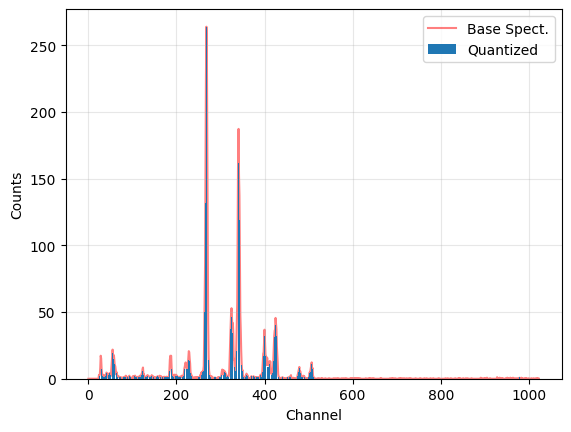

In [42]:
CHANNELS = 1024
ADDR_WIDTH = 12
DAC_WIDTH = 14

route = "../specs/Am241_gain20_1024_norm.txt"

# Generate and save LUT
spec, ch_freqs, counts = quant_ampl_dist(
    route,
    CHANNELS,
    ADDR_WIDTH,
    DAC_WIDTH,
    save=True
)


plt.bar(range(CHANNELS), counts, label = 'Quantized', zorder = 2)
plt.plot(range(CHANNELS), spec*counts.max()/spec.max(), 'r', label = 'Base Spect.', alpha = 0.5, zorder = 0)
plt.xlabel("Channel")
plt.ylabel("Counts")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


In [ ]:
samples = 512

# Define the synthetic detector pulse shape using a bi-exponential model
def biexp(t, A, tau_f, tau_s):
    y = A * (np.exp(-t / tau_f) - np.exp(-t / tau_s))
    return -y


# Generate time axis for pulse definition
t = np.linspace(0, 30e-6, samples)

# Define bi-exponential pulse model parameters
A = 1.0
tau_f = 0.4e-6   # Fast component time constant
tau_s = 7e-6     # Slow component time constant

# Compute synthetic pulse waveform
y = biexp(t, A, tau_f, tau_s)

# Normalize pulse amplitude and quantize to DAC resolution
DAC_MAX = 2**DAC_WIDTH - 2  # Reserve maximum DAC code to avoid saturation

y = y / np.max(np.abs(y))
y = np.uint32(np.abs(y) * DAC_MAX)

# Save quantized pulse waveform as a binary file
output_path = "../pulses/biexp.bin"
y.tofile(output_path)

# Verify generated lookup table properties
print("NUMBER OF SAMPLES :", len(y))
print("DAC MIN           :", y.min())
print("DAC MAX           :", y.max())
print("DAC LIMIT         :", DAC_MAX)
print("ARCHIVE SIZE      :", y.nbytes, "bytes")
print("OUTPUT FILE       :", output_path)